# Detección multiclase de DDoS en el campus SDN

Este cuaderno responde qué se puede detectar con los datos que ya están
en el repositorio: los flujos de `data/processed/` y el efecto sobre el
portal en `data/metrics/resumen.csv`.

No usa la dirección IP. Las diez PCs infectadas aparecen como `BENIGN`
en el baseline y como ataque en los otros archivos, así que memorizar
la IP no sirve. El modelo tiene que usar el comportamiento del flujo.

La prueba deja fuera un laboratorio entero (Ciencias Agrarias, `10.5`)
y entrena con los otros cuatro.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / "data" / "processed").is_dir():
    ROOT = ROOT.parent
PROC = ROOT / "data" / "processed"
METRICS = ROOT / "data" / "metrics" / "resumen.csv"
OUT = ROOT / "notebooks" / "resultados"
OUT.mkdir(parents=True, exist_ok=True)

LABS = {
    "10.1": "Salud",
    "10.2": "Ingenierias",
    "10.3": "Administracion",
    "10.4": "Sociales",
    "10.5": "Agrarias",
}
HOLDOUT = "10.5"
IDENTIDAD = ["src_ip", "dst_ip", "src_port", "dst_port", "timestamp"]
ORDEN = ["BENIGN", "httpflood", "icmpflood", "slowloris", "synflood"]

plt.rcParams["figure.dpi"] = 120
print("Datos:", PROC)


Datos: /Users/alessandro/Project/UNCP/sdn-ddos-multiclass-detection/data/processed


## Qué sintió el alumno

`resumen.csv` no es un flujo: es la sonda de `salud-u1`, una vez por
segundo. Ahí se ve si la página abrió, cuánto tardó y cuántos paquetes
entraron al portal. Un detector de flujos y esta sonda responden
preguntas distintas.


In [2]:
resumen = pd.read_csv(METRICS)
resumen["http_ok_rate"] = resumen["http_200"] / resumen["samples"].replace(0, np.nan)
base = resumen.loc[resumen["scenario"] == "baseline"].iloc[0]
vista = resumen.copy()
vista["latencia_vs_baseline"] = vista["latency_ms_avg"] / base["latency_ms_avg"]
vista["paquetes_vs_baseline"] = vista["server_rx_pps_avg"] / base["server_rx_pps_avg"]
columnas = [
    "scenario", "duration_s", "http_ok_rate", "latency_ms_avg",
    "latencia_vs_baseline", "server_rx_pps_avg", "paquetes_vs_baseline",
]
vista[columnas].round(3)


,scenario,duration_s,http_ok_rate,latency_ms_avg,latencia_vs_baseline,server_rx_pps_avg,paquetes_vs_baseline
0,synflood,120,1.000,403.2,0.996,472.5,4.211
1,httpflood,120,1.000,545.4,1.348,375.9,3.350
2,slowloris,120,0.008,403.9,0.998,72.0,0.642
3,icmpflood,120,1.000,403.3,0.997,270.9,2.414
4,baseline,30,1.000,404.7,1.000,112.2,1.000


## Flujos que sí se pueden clasificar

Cada fila de `data/processed/*.csv` es un flujo con la etiqueta puesta
por IP de origen en el momento de la captura. Aquí se juntan los cinco
escenarios. Se quitan las respuestas del portal (`10.0.0.10`): no son
quien abre la conexión.


Flujos de clientes: 40898
IPs que son benignas y tambien ataque: 10
Esas IPs no pueden ser la regla. Ejemplo: 10.1.0.20 -> ('BENIGN', 'httpflood', 'icmpflood', 'slowloris', 'synflood')


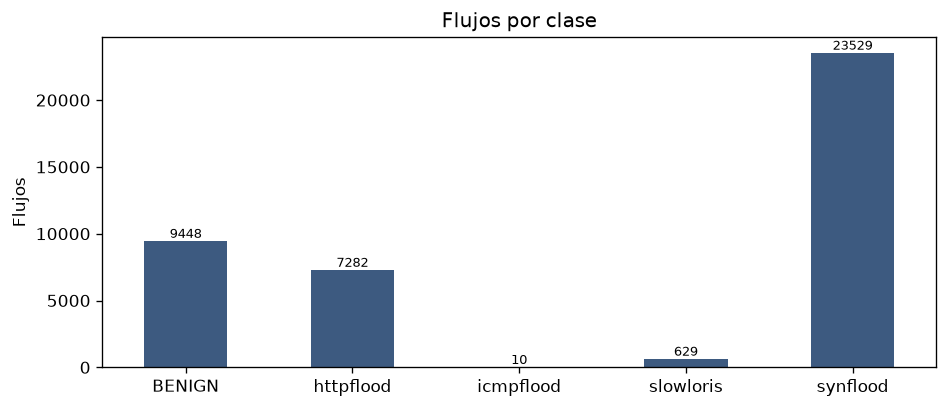

,flujos
Label,
BENIGN,9448
httpflood,7282
icmpflood,10
slowloris,629
synflood,23529


In [3]:
frames = [pd.read_csv(path) for path in sorted(PROC.glob("*.csv"))]
raw = pd.concat(frames, ignore_index=True)
raw["lab"] = raw["src_ip"].str.extract(r"^(10\.\d+)", expand=False)
clientes = raw[raw["lab"].isin(LABS)].copy()

por_ip = clientes.groupby("src_ip")["Label"].agg(lambda s: tuple(sorted(set(s))))
varias = por_ip[por_ip.map(len) > 1]
print("Flujos de clientes:", len(clientes))
print("IPs que son benignas y tambien ataque:", len(varias))
print("Esas IPs no pueden ser la regla. Ejemplo:", varias.index[0], "->", varias.iloc[0])

conteo = clientes["Label"].value_counts().reindex(ORDEN)
fig, ax = plt.subplots(figsize=(8, 3.5))
conteo.plot(kind="bar", ax=ax, color="#3d5a80", rot=0)
ax.set_ylabel("Flujos")
ax.set_xlabel("")
ax.set_title("Flujos por clase")
for i, valor in enumerate(conteo.fillna(0)):
    ax.text(i, valor, str(int(valor)), ha="center", va="bottom", fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "clases.png")
plt.show()
conteo.to_frame("flujos")


## Entrenamiento

Se sacan IP, puertos y marca de tiempo. Esas columnas dicen quién es,
no cómo se comporta. Ciencias Agrarias no entra al entrenamiento.

Hay dos modelos. La regresión logística es la línea de base, fácil de
explicar. El bosque aleatorio aguanta mejor columnas en escalas distintas.
Los dos equilibran las clases: si no, el modelo solo aprendería el SYN
flood, que es la mayoría de las filas.


In [4]:
trabajo = clientes.copy()
features = [c for c in trabajo.columns if c not in IDENTIDAD + ["Label", "lab"]]
X = trabajo[features].apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)
y = trabajo["Label"]
lab = trabajo["lab"]

entrenar = lab != HOLDOUT
probar = lab == HOLDOUT
X_train, X_test = X.loc[entrenar], X.loc[probar]
y_train, y_test = y.loc[entrenar], y.loc[probar]
vary = [c for c in X_train.columns if X_train[c].nunique() > 1]
X_train, X_test = X_train[vary], X_test[vary]

print("Entrena con", sorted(lab[entrenar].unique()), "filas", len(X_train))
print("Prueba en", LABS[HOLDOUT], "filas", len(X_test), "columnas", len(vary))
print("Clases en la prueba:")
print(y_test.value_counts().reindex(ORDEN).fillna(0).astype(int).to_string())

modelos = {
    "logistica": Pipeline([
        ("escala", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced")),
    ]),
    "bosque": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    ),
}
pred = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred[nombre] = modelo.predict(X_test)
    macro = f1_score(y_test, pred[nombre], average="macro", zero_division=0)
    print("%s  F1 macro %.3f" % (nombre, macro))

ganador = max(pred, key=lambda n: f1_score(y_test, pred[n], average="macro", zero_division=0))
print("Mejor modelo:", ganador)


Entrena con ['10.1', '10.2', '10.3', '10.4'] filas 32829
Prueba en Agrarias filas 8069 columnas 56
Clases en la prueba:
Label
BENIGN       1779
httpflood    1456
icmpflood       2
slowloris     126
synflood     4706


logistica  F1 macro 0.959


bosque  F1 macro 0.986
Mejor modelo: bosque


## Resultado por clase

La métrica que importa aquí es el F1 de cada clase, no el acierto global.
El SYN flood son decenas de miles de flujos; un modelo que siempre diga
`synflood` acertaría mucho y no detectaría nada más.


In [5]:
reporte = pd.DataFrame(
    classification_report(y_test, pred[ganador], zero_division=0, output_dict=True)
).T
reporte = reporte.round(3)
reporte.to_csv(OUT / "reporte_clases.csv")
reporte


,precision,recall,f1-score,support
BENIGN,0.972,0.966,0.969,1779.000
httpflood,0.958,0.966,0.962,1456.000
icmpflood,1.000,1.000,1.000,2.000
slowloris,1.000,1.000,1.000,126.000
synflood,1.000,1.000,1.000,4706.000
accuracy,0.986,0.986,0.986,0.986
macro avg,0.986,0.986,0.986,8069.000
weighted avg,0.986,0.986,0.986,8069.000


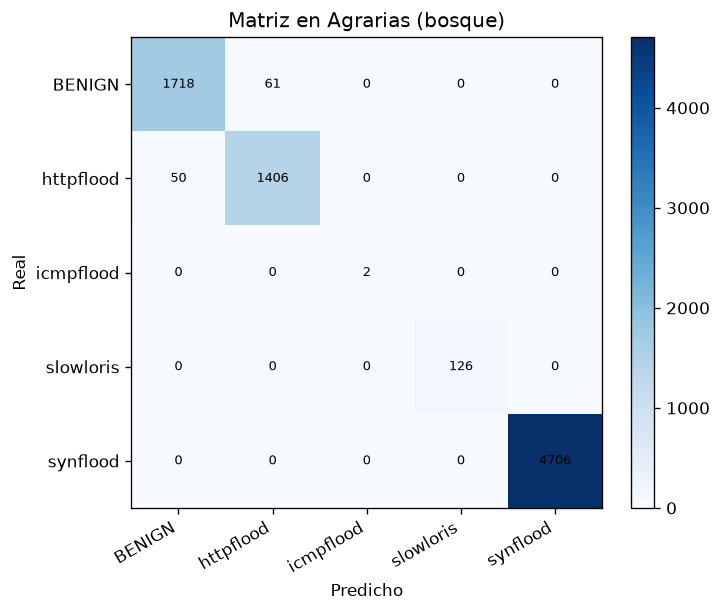

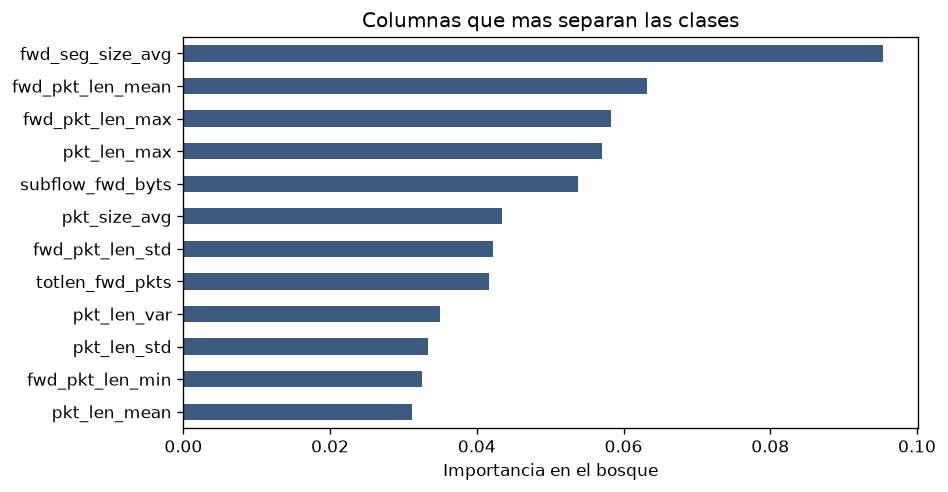

,importancia
fwd_seg_size_avg,0.095
fwd_pkt_len_mean,0.063
fwd_pkt_len_max,0.058
pkt_len_max,0.057
subflow_fwd_byts,0.054
pkt_size_avg,0.043
fwd_pkt_len_std,0.042
totlen_fwd_pkts,0.042
pkt_len_var,0.035
pkt_len_std,0.033


In [6]:
def dibujar_matriz(y_true, y_pred, titulo, path):
    presentes = set(y_true) | set(y_pred)
    labels = [c for c in ORDEN if c in presentes]
    labels += sorted(presentes - set(labels))
    matriz = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    im = ax.imshow(matriz, cmap="Blues")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.set_title(titulo)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            ax.text(j, i, str(matriz[i, j]), ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(path)
    plt.show()

dibujar_matriz(
    y_test, pred[ganador],
    "Matriz en %s (%s)" % (LABS[HOLDOUT], ganador),
    OUT / "matriz.png",
)

bosque = modelos["bosque"]
importancias = pd.Series(bosque.feature_importances_, index=vary).sort_values(ascending=False)
top = importancias.head(12).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
top.plot(kind="barh", ax=ax, color="#3d5a80")
ax.set_xlabel("Importancia en el bosque")
ax.set_title("Columnas que mas separan las clases")
fig.tight_layout()
fig.savefig(OUT / "importancia.png")
plt.show()
top.sort_values(ascending=False).round(3).to_frame("importancia")


## Ataque sí o no

La misma partición, pero juntando los cuatro vectores en una sola clase
`ATAQUE`. Sirve para ver si el flujo maligno se separa del alumno aunque
el tipo exacto falle.


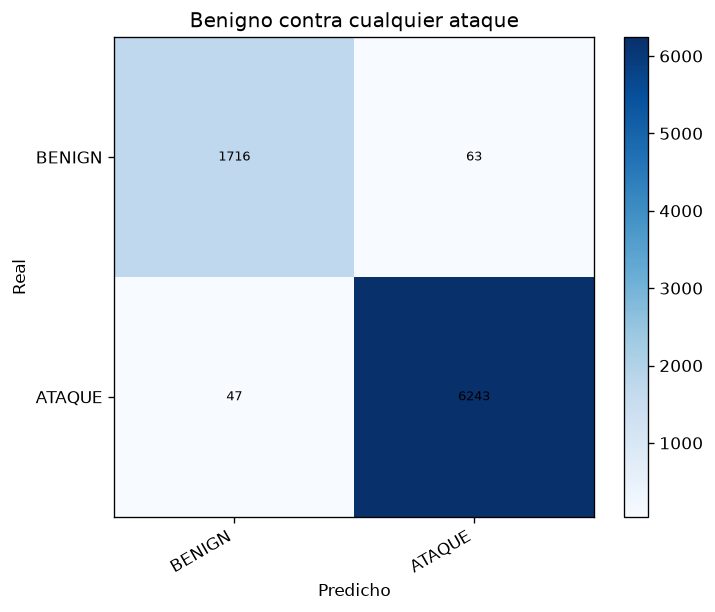

,precision,recall,f1-score,support
ATAQUE,0.990,0.993,0.991,6290.000
BENIGN,0.973,0.965,0.969,1779.000
accuracy,0.986,0.986,0.986,0.986
macro avg,0.982,0.979,0.980,8069.000
weighted avg,0.986,0.986,0.986,8069.000


In [7]:
y_bin_train = np.where(y_train == "BENIGN", "BENIGN", "ATAQUE")
y_bin_test = np.where(y_test == "BENIGN", "BENIGN", "ATAQUE")
binario = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)
binario.fit(X_train, y_bin_train)
pred_bin = binario.predict(X_test)
bin_reporte = pd.DataFrame(
    classification_report(y_bin_test, pred_bin, zero_division=0, output_dict=True)
).T.round(3)
bin_reporte.to_csv(OUT / "reporte_binario.csv")
dibujar_matriz(y_bin_test, pred_bin, "Benigno contra cualquier ataque", OUT / "matriz_binaria.png")
bin_reporte


## Qué queda detectado, y qué no

La tabla de abajo cruza las dos fuentes. "En el flujo" sale del modelo
sobre Ciencias Agrarias. "En la página" sale de la sonda: si el alumno
sigue recibiendo 200, si la espera crece, o si solo sube el ritmo de
paquetes.


In [8]:
filas = reporte.loc[[c for c in ORDEN if c in reporte.index], ["precision", "recall", "f1-score", "support"]]

def juicio_flujo(fila):
    if fila["support"] < 30:
        return "hay muy pocos flujos para afirmarlo"
    if fila["precision"] >= 0.85 and fila["recall"] >= 0.85:
        return "se distingue bien"
    if fila["f1-score"] >= 0.6:
        return "se distingue en parte"
    return "no queda bien separado"

def juicio_pagina(nombre):
    if nombre == "BENIGN":
        return "es el tráfico de referencia"
    fila = resumen.loc[resumen["scenario"] == nombre]
    if fila.empty:
        return "sin sonda"
    fila = fila.iloc[0]
    ok = fila["http_200"] / fila["samples"] if fila["samples"] else 0
    notas = []
    if ok < 0.5:
        notas.append("la pagina deja de abrir")
    elif fila["latency_ms_avg"] > base["latency_ms_avg"] * 1.2:
        notas.append("la pagina tarda mas")
    if fila["server_rx_pps_avg"] > base["server_rx_pps_avg"] * 1.5:
        notas.append("suben los paquetes al portal")
    if not notas:
        notas.append("la pagina sigue respondiendo parecido al baseline")
    return "; ".join(notas)

cierre = filas.copy()
cierre["en_el_flujo"] = cierre.apply(juicio_flujo, axis=1)
cierre["en_la_pagina"] = [juicio_pagina(nombre) for nombre in cierre.index]
cierre.to_csv(OUT / "que_se_detecta.csv")
print("Modelo usado:", ganador)
print("F1 macro:", round(f1_score(y_test, pred[ganador], average="macro", zero_division=0), 3))
print("F1 del detector binario (macro):", round(f1_score(y_bin_test, pred_bin, average="macro", zero_division=0), 3))
cierre.round(3)


Modelo usado: bosque
F1 macro: 0.986
F1 del detector binario (macro): 0.98


,precision,recall,f1-score,support,en_el_flujo,en_la_pagina
BENIGN,0.972,0.966,0.969,1779.0,se distingue bien,es el tráfico de referencia
httpflood,0.958,0.966,0.962,1456.0,se distingue bien,la pagina tarda mas; suben los paquetes al portal
icmpflood,1.000,1.000,1.000,2.0,hay muy pocos flujos para afirmarlo,suben los paquetes al portal
slowloris,1.000,1.000,1.000,126.0,se distingue bien,la pagina deja de abrir
synflood,1.000,1.000,1.000,4706.0,se distingue bien,suben los paquetes al portal


## Límite de esta corrida

Esto no es un detector en el controlador. Clasifica flujos ya capturados,
de una sola pasada por escenario, con el portal de prueba (0,4 s y 30
conexiones). `icmpflood` tiene del orden de diez flujos en todo el
dataset: si el juicio dice que hay muy pocos, no se puede publicar esa
clase como resultado firme hasta capturar más.

Para repetir el cuaderno, desde la raíz del repositorio y con el entorno
ya creado:

```bash
.venv/bin/python -m jupyter nbconvert --execute --inplace notebooks/deteccion_ddos.ipynb
```

Las tablas y las figuras quedan en `notebooks/resultados/`.
